### Data Exploration Process
##### Main Goal: To understand the structure, coverage, quality of the data before proceeding with further cleaning and analysis
#### List Of Exploration
- How large is the dataset, and what columns are available?
- Which commodities and time periods have the most complete data?
- Does data coverage vary across regions or over time?
- What are the data limitations that should be considered before drawing business conclusions?


### 01 - Import Libraries

In [50]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path


### 02 - Load Data


In [51]:
DATA_PATH = r"D:\food-price-project\data\bronze\IDN_RTFP_mkt_2007_2026-10-05.csv"

try:
    df = pd.read_csv(DATA_PATH, low_memory=False, header=0, index_col=False, delimiter=',', encoding='utf-8')
except Exception as e:
    print(f"Failed to read file: {e}")

print(f"Rows: {df.shape[0]:,}")
print(f"Columns: {df.shape[1]:,}")
display(df.head())

Rows: 53,074
Columns: 88


,ISO3,country,adm1_name,adm2_name,mkt_name,lat,lon,geo_id,price_date,year,...,l_sugar,c_sugar,inflation_sugar,trust_sugar,o_food_price_index,h_food_price_index,l_food_price_index,c_food_price_index,inflation_food_price_index,trust_food_price_index
0,IDN,Indonesia,SULAWESI UTARA,KOTA KOTAMOBAGU,Pasar 23 Maret,0.74,124.31,gid_74000001243100000,2007-01-01,2007,...,10690.99,10833.82,NaN,8.6,0.62,0.63,0.60,0.62,NaN,9.0
1,IDN,Indonesia,SULAWESI UTARA,KOTA KOTAMOBAGU,Pasar 23 Maret,0.74,124.31,gid_74000001243100000,2007-02-01,2007,...,10691.59,11020.36,NaN,8.6,0.62,0.63,0.61,0.61,NaN,9.0
2,IDN,Indonesia,SULAWESI UTARA,KOTA KOTAMOBAGU,Pasar 23 Maret,0.74,124.31,gid_74000001243100000,2007-03-01,2007,...,10870.22,11247.83,NaN,8.6,0.61,0.63,0.60,0.62,NaN,9.0
3,IDN,Indonesia,SULAWESI UTARA,KOTA KOTAMOBAGU,Pasar 23 Maret,0.74,124.31,gid_74000001243100000,2007-04-01,2007,...,11044.15,11044.15,NaN,8.6,0.62,0.64,0.61,0.64,NaN,9.0
4,IDN,Indonesia,SULAWESI UTARA,KOTA KOTAMOBAGU,Pasar 23 Maret,0.74,124.31,gid_74000001243100000,2007-05-01,2007,...,10588.70,10588.70,NaN,8.6,0.64,0.65,0.63,0.63,NaN,9.0


### 03 - Understand The Dataset


In [52]:
print("\nColumn names:")
print(df.columns.tolist())

# Range Date
display(df["price_date"].min() + " to " +  df["price_date"].max())

display(df.info())




Column names:
['ISO3', 'country', 'adm1_name', 'adm2_name', 'mkt_name', 'lat', 'lon', 'geo_id', 'price_date', 'year', 'month', 'currency', 'components', 'start_dense_data', 'last_survey_point', 'data_coverage', 'data_coverage_recent', 'index_confidence_score', 'spatially_interpolated', 'chili', 'eggs', 'garlic', 'meat_chicken', 'meat_chicken_broiler', 'oil', 'onions', 'rice', 'sugar', 'o_chili', 'h_chili', 'l_chili', 'c_chili', 'inflation_chili', 'trust_chili', 'o_eggs', 'h_eggs', 'l_eggs', 'c_eggs', 'inflation_eggs', 'trust_eggs', 'o_garlic', 'h_garlic', 'l_garlic', 'c_garlic', 'inflation_garlic', 'trust_garlic', 'o_meat_chicken', 'h_meat_chicken', 'l_meat_chicken', 'c_meat_chicken', 'inflation_meat_chicken', 'trust_meat_chicken', 'o_meat_chicken_broiler', 'h_meat_chicken_broiler', 'l_meat_chicken_broiler', 'c_meat_chicken_broiler', 'inflation_meat_chicken_broiler', 'trust_meat_chicken_broiler', 'o_oil', 'h_oil', 'l_oil', 'c_oil', 'inflation_oil', 'trust_oil', 'o_onions', 'h_onions',

'2007-01-01 to 2026-10-01'

<class 'pandas.DataFrame'>
RangeIndex: 53074 entries, 0 to 53073
Data columns (total 88 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   ISO3                            53074 non-null  str    
 1   country                         53074 non-null  str    
 2   adm1_name                       53074 non-null  str    
 3   adm2_name                       53074 non-null  str    
 4   mkt_name                        53074 non-null  str    
 5   lat                             52836 non-null  float64
 6   lon                             52836 non-null  float64
 7   geo_id                          53074 non-null  str    
 8   price_date                      53074 non-null  str    
 9   year                            53074 non-null  int64  
 10  month                           53074 non-null  int64  
 11  currency                        53074 non-null  str    
 12  components                      53074 non-n

None

### 04 - Data Coverage Check

In [53]:
# Range of Area to analyze

print("Total Province: ", df["adm1_name"].nunique())
print("List of Province: ", df["adm1_name"].unique())

print("Total City/District: ", df["adm2_name"].nunique())
print("List of City/District: ", df["adm2_name"].unique())


# Group By City/District By its province
grouped = df.groupby("adm1_name")["adm2_name"]
df_list = grouped.apply(lambda x: list(x.unique())).reset_index()
df_counts = grouped.nunique().reset_index()

display(df_list, df_counts)



Total Province:  35
List of Province:  <ArrowStringArray>
[            'SULAWESI UTARA',             'SUMATERA UTARA',
           'KALIMANTAN UTARA',                 'JAWA BARAT',
        'NUSA TENGGARA BARAT',        'NUSA TENGGARA TIMUR',
           'SULAWESI SELATAN',                      'JAMBI',
                 'JAWA TIMUR',         'KALIMANTAN SELATAN',
                       'BALI',                     'BANTEN',
                'JAWA TENGAH',                       'RIAU',
             'SUMATERA BARAT',             'KEPULAUAN RIAU',
                      'PAPUA',             'SULAWESI BARAT',
                   'BENGKULU',               'MALUKU UTARA',
 'DAERAH ISTIMEWA YOGYAKARTA',           'KALIMANTAN BARAT',
          'KALIMANTAN TENGAH',                'PAPUA BARAT',
           'SUMATERA SELATAN',                     'MALUKU',
  'KEPULAUAN BANGKA BELITUNG',                       'ACEH',
                'DKI JAKARTA',          'SULAWESI TENGGARA',
                  'GORONTAL

,adm1_name,adm2_name
0,ACEH,"[KOTA LHOKSEUMAWE, ACEH BARAT, KOTA BANDA ACEH]"
1,BALI,"[BULELENG, KOTA DENPASAR]"
2,BANTEN,"[KOTA TANGERANG, KOTA CILEGON, KOTA SERANG]"
3,BENGKULU,[KOTA BENGKULU]
4,DAERAH ISTIMEWA YOGYAKARTA,[KOTA YOGYAKARTA]
5,DKI JAKARTA,"[KOTA JAKARTA TIMUR, KOTA JAKARTA SELATAN]"
6,GORONTALO,"[GORONTALO, KOTA GORONTALO]"
7,JAMBI,"[KOTA JAMBI, BUNGO]"
8,JAWA BARAT,"[KOTA DEPOK, KOTA BOGOR, KOTA TASIKMALAYA, KOT..."
9,JAWA TENGAH,"[KOTA TEGAL, KARANGANYAR, KUDUS, SRAGEN, KLATE..."


,adm1_name,adm2_name
0,ACEH,3
1,BALI,2
2,BANTEN,3
3,BENGKULU,1
4,DAERAH ISTIMEWA YOGYAKARTA,1
5,DKI JAKARTA,2
6,GORONTALO,2
7,JAMBI,2
8,JAWA BARAT,9
9,JAWA TENGAH,12


In [54]:
commodities = [
    "rice", "oil", "sugar", "eggs", "chili",
    "meat_chicken", "meat_chicken_broiler", "garlic", "onions"
]

# Coverage By Year
if commodities:
    coverage_by_year = (
        df.assign(_year=pd.to_numeric(df["year"], errors="coerce"))
          .groupby("_year")[commodities]
          .agg(lambda s: s.notna().mean() * 100)
          .round(1)
    )
    coverage_by_year.index.name = "year"
    display(coverage_by_year)
else:
    coverage_by_year = pd.DataFrame()
    print("No commodities specified for coverage analysis.")

,rice,oil,sugar,eggs,chili,meat_chicken,meat_chicken_broiler,garlic,onions
year,,,,,,,,,
2007,0.0,0.0,0.0,0.4,0.4,0.0,0.4,0.0,0.0
2008,0.0,0.0,0.0,0.4,0.4,0.0,0.4,0.0,0.0
2009,0.0,0.0,0.0,0.4,0.4,0.0,0.4,0.0,0.0
2010,0.0,0.0,0.0,0.4,0.4,0.0,0.4,0.0,0.0
2011,0.0,0.0,0.0,0.4,0.4,0.0,0.4,0.0,0.0
2012,0.0,0.0,0.0,0.4,0.4,0.0,0.4,0.0,0.0
2013,0.0,0.0,0.0,0.4,0.4,0.0,0.4,0.0,0.0
2014,0.0,0.0,0.0,0.4,0.4,0.0,0.4,0.0,0.0
2015,0.0,0.0,0.0,0.4,0.4,0.0,0.4,0.0,0.0


,rice,oil,sugar,eggs,chili,meat_chicken,meat_chicken_broiler,garlic,onions
month,,,,,,,,,
2007-01-01,0.0,0.0,0.0,0.4,0.4,0.0,0.4,0.0,0.0
2007-02-01,0.0,0.0,0.0,0.4,0.4,0.0,0.4,0.0,0.0
2007-03-01,0.0,0.0,0.0,0.4,0.4,0.0,0.4,0.0,0.0
2007-04-01,0.0,0.0,0.0,0.4,0.4,0.0,0.4,0.0,0.0
2007-05-01,0.0,0.0,0.0,0.4,0.4,0.0,0.4,0.0,0.0
...,...,...,...,...,...,...,...,...,...
2026-06-01,95.1,95.1,95.1,96.4,0.0,94.6,0.0,96.0,96.4
2026-07-01,93.3,93.7,93.3,94.2,0.0,93.3,0.0,95.1,93.7
2026-08-01,94.6,95.5,95.1,96.0,0.0,94.2,0.0,95.5,95.5


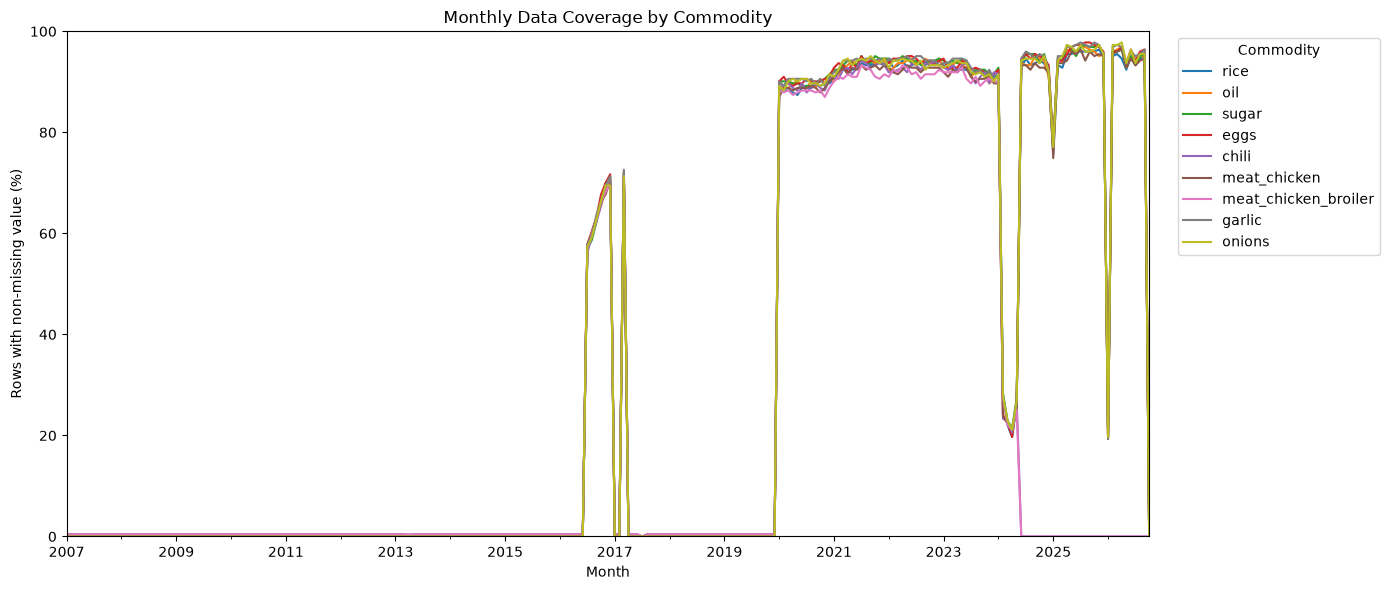

In [55]:
#Coverage By Month

df["price_date_parsed"] = pd.to_datetime(df["price_date"], errors="coerce")

temp = df.loc[df["price_date_parsed"].notna(), ["price_date_parsed"] + commodities].copy()
temp["month"] = temp["price_date_parsed"].dt.to_period("M").dt.to_timestamp()

coverage_by_month = (
    temp.groupby("month")[commodities]
        .agg(lambda s: s.notna().mean() * 100)
        .round(1)
)

display(coverage_by_month)

# Plot coverage monthly
ax = coverage_by_month.plot(figsize=(14, 6), linewidth=1.5)
ax.set_title("Monthly Data Coverage by Commodity")
ax.set_xlabel("Month")
ax.set_ylabel("Rows with non-missing value (%)")
ax.set_ylim(0, 100)
plt.legend(title="Commodity", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()


#### Findings
- 53,074 rows = 223 geo_id x 238 months (2007-01 to 2026-10), 88 columns.
- "Market Average" is an aggregate row (1 geo_id, no coordinates), not a market. Excluding it leaves 222 markets and 34 provinces.
- Observed prices are ~0% before 2020 (exceptions: ~32% in 2016, ~6% in 2017) and ~89-95% from 2020, so earlier c_ values are mostly model estimates.
- Chili and broiler chicken have 0% observed prices in 2025-2026 -> excluded.
- Coverage dips in Jan 2025 (~77%) and Jan 2026 (~20%); Oct 2026 is 0% (month not finished) -> excluded.
- Decision: period 2020-01 to 2026-09; commodities: rice, oil, sugar, eggs, meat_chicken, onions.

#### Columns to be used
- Identity/time: geo_id, mkt_name, adm1_name, adm2_name, lat, lon, price_date
- Per commodity (rice, oil, sugar, eggs, meat_chicken, onions): c_<com> (price), <com> (observed price), inflation_<com> (YoY %), trust_<com>
- Dropped: ISO3, country, currency, spatially_interpolated (constant); metadata columns; o_/h_/l_; chili, meat_chicken_broiler, garlic; food_price_index

In [56]:
COMMODITIES_USED = ["rice", "oil", "sugar", "eggs", "meat_chicken", "onions"]
ID_COLS = ["geo_id", "mkt_name", "adm1_name", "adm2_name", "lat", "lon", "price_date"]
patterns = ["c_{}", "{}", "inflation_{}", "trust_{}"]

cols_used = ID_COLS + [p.format(c) for c in COMMODITIES_USED for p in patterns]
